In [16]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam

In [21]:
data = pd.read_csv(r'D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\FNN and CNN\CIFAR10\cifar-10.csv', dtype=np.uint8)

In [25]:
X = data.drop('label', axis=1).values
y = data['label'].values

In [26]:
X = X / 255.0

In [27]:
X = X.reshape(-1,32,32,3)

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [29]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (40000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


In [30]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)),

    MaxPooling2D((2,2)),
    Dropout(0.25),

    Conv2D(64, (3,3), activation='relu'),

    MaxPooling2D((2,2)),
    Dropout(0.25),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.25),

    Dense(10, activation='softmax')
])

model.summary()

C:\Users\SAKSHI\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)                    │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [31]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [32]:
history = model.fit(
    X_train, y_train,
    epochs = 10,
    batch_size=16,
    validation_split=0.1
)

Epoch 1/10
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 133s 57ms/step - accuracy: 0.3798 - loss: 1.7115 - val_accuracy: 0.4997 - val_loss: 1.4190
Epoch 2/10
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 145s 64ms/step - accuracy: 0.4849 - loss: 1.4392 - val_accuracy: 0.5560 - val_loss: 1.2783
Epoch 3/10
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 294s 105ms/step - accuracy: 0.5234 - loss: 1.3381 - val_accuracy: 0.5763 - val_loss: 1.2189
Epoch 4/10
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 32s 14ms/step - accuracy: 0.5469 - loss: 1.2746 - val_accuracy: 0.5660 - val_loss: 1.2423
Epoch 5/10
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 34s 15ms/step - accuracy: 0.5619 - loss: 1.2304 - val_accuracy: 0.6020 - val_loss: 1.1736
Epoch 6/10
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 31s 14ms/step - accuracy: 0.5799 - loss: 1.1901 - val_accuracy: 0.6177 - val_loss: 1.1326
Epoch 7/10
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 42s 18ms/step - accuracy: 0.5886 - loss: 1.1614 - val_accuracy: 0.6005 - val_loss: 1.1485
Epoch 8/10
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 31s 14ms/step - accuracy: 0.60

In [33]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6155 - loss: 1.0980
Test Loss: 1.0980148315429688
Test Accuracy: 0.6154999732971191


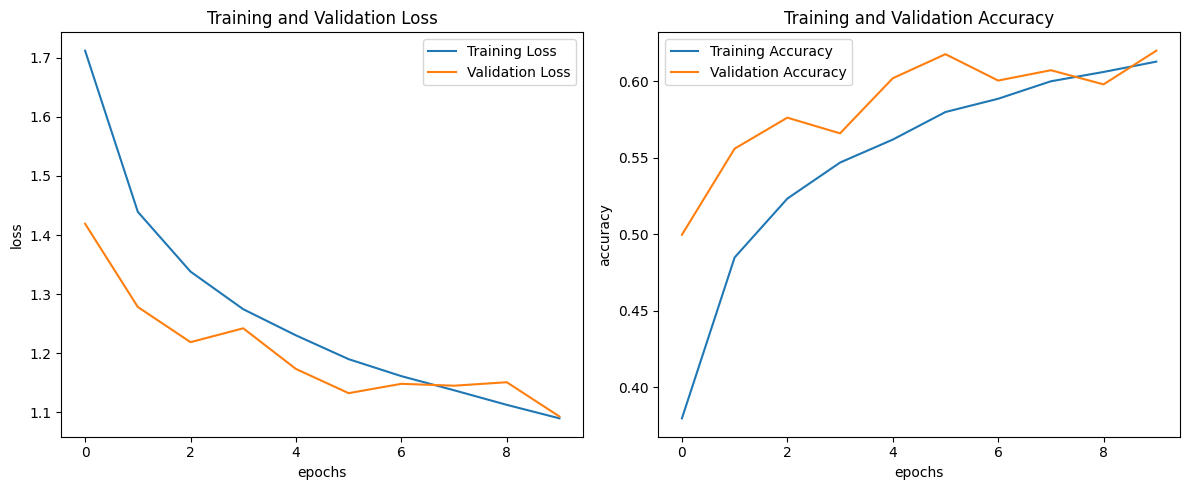

In [34]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.legend()

plt.tight_layout()
plt.show()